In [4]:
# 도구 import
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

import sys
import numpy as np
import pandas as pd
import seaborn as sns

print(f"Python Version: {sys.version}")
print(f"Numpy Version : {np.__version__}")
print(f"Pandas version: {pd.__version__}")
print(f"Seaborn Version: {sns.__version__}")

import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False


Python Version: 3.15.1 (tags/v3.15.1:c37e74c, Oct 21 2026, 06:24:08) [MSC v.1951 64 bit (AMD64)]
Numpy Version : 2.5.4
Pandas version: 3.1.0
Seaborn Version: 0.13.2


In [5]:
# 데이터 로드 및 확인
data = pd.read_csv("Data/givemesomecredit.csv")
data.head(5)
data.shape


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfDependents,CombinedDefaulted,CombinedCreditLoans
0,1,0.766127,45,2,0.802982,9120,2,1,1
1,0,0.957151,40,0,0.121876,2600,1,0,0
2,0,0.658180,38,1,0.085113,3042,0,1,0
3,0,0.233810,30,0,0.036050,3300,0,0,0
4,0,0.907239,49,1,0.024926,63588,0,1,1


(150000, 9)

In [6]:
# 기술통계, 왜도, 결측치, 타입 정리
d = data.dtypes
n = data.isnull().sum()
s = data.skew()
dn = pd.DataFrame((s, n, d), index=['skew', 'isnull', 'dtypes']).T
desc = data.describe().T
result = pd.concat([desc, dn],axis=1)
print("각 변수에 대해 기술통계 및 타입, 결측치 여부")
result

각 변수에 대해 기술통계 및 타입, 결측치 여부


,count,mean,std,min,25%,50%,75%,max,skew,isnull,dtypes
SeriousDlqin2yrs,150000.0,0.066840,0.249746,0.0,0.000000,0.000000,0.000000,1.0,3.468857,0,int64
RevolvingUtilizationOfUnsecuredLines,150000.0,6.048438,249.755371,0.0,0.029867,0.154181,0.559046,50708.0,97.631574,0,float64
age,150000.0,52.295553,14.771249,21.0,41.000000,52.000000,63.000000,109.0,0.189244,0,int64
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.421033,4.192781,0.0,0.000000,0.000000,0.000000,98.0,22.597108,0,int64
DebtRatio,150000.0,353.005076,2037.818523,0.0,0.175074,0.366508,0.868254,329664.0,95.157793,0,float64
MonthlyIncome,150000.0,6673.266053,12880.469331,0.0,3903.000000,6600.000000,7400.000000,3008750.0,127.356561,0,int64
NumberOfDependents,150000.0,0.737413,1.107021,0.0,0.000000,0.000000,1.000000,20.0,1.626059,0,int64
CombinedDefaulted,150000.0,0.202420,0.401805,0.0,0.000000,0.000000,0.000000,1.0,1.481236,0,int64
CombinedCreditLoans,150000.0,0.742500,0.437259,0.0,0.000000,1.000000,1.000000,1.0,-1.109198,0,int64


클래스 각 분류의 개수


,count
SeriousDlqin2yrs,
0,139974
1,10026


<Axes: xlabel='SeriousDlqin2yrs'>

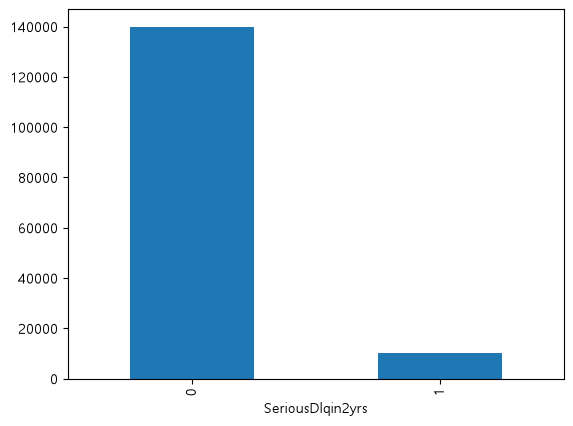

Class(SeriousDlqin2yrs) 에 대해 0과 1의 비율이 93.3:6.7, IR은 13.961로, 매우 불균형함을 보이고 있음.


In [7]:
# 클래스 분석
cls = data["SeriousDlqin2yrs"].value_counts()
print("클래스 각 분류의 개수")
cls.to_frame()
cls.plot(kind='bar')
plt.show()
dlqratio = (cls[0] / cls.sum() * 100).round(1)

print(f"Class(SeriousDlqin2yrs) 에 대해 0과 1의 비율이 {dlqratio}:{(100 - dlqratio).round(1)}, IR은 {(cls[0]/cls[1]).round(3)}로, 매우 불균형함을 보이고 있음.")


array([[<Axes: title={'center': 'SeriousDlqin2yrs'}>,
        <Axes: title={'center': 'RevolvingUtilizationOfUnsecuredLines'}>,
        <Axes: title={'center': 'age'}>],
       [<Axes: title={'center': 'NumberOfTime30-59DaysPastDueNotWorse'}>,
        <Axes: title={'center': 'DebtRatio'}>,
        <Axes: title={'center': 'MonthlyIncome'}>],
       [<Axes: title={'center': 'NumberOfDependents'}>,
        <Axes: title={'center': 'CombinedDefaulted'}>,
        <Axes: title={'center': 'CombinedCreditLoans'}>]], dtype=object)

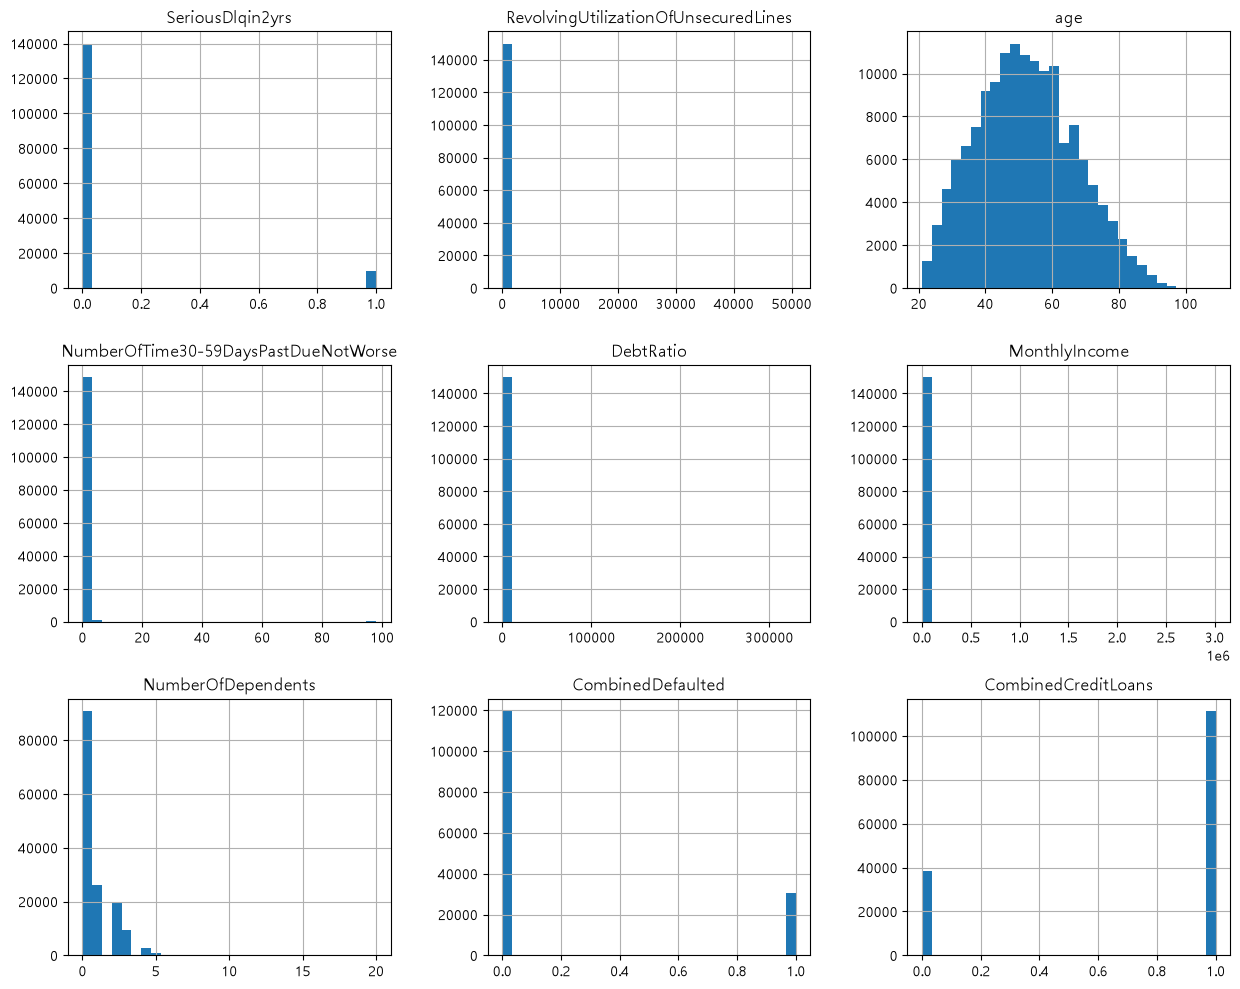

In [8]:
# 데이터 히스토그램
data.hist(figsize=(15,12), bins=30)

array([[<Axes: ylabel='Density'>, <Axes: ylabel='Density'>,
        <Axes: ylabel='Density'>],
       [<Axes: ylabel='Density'>, <Axes: ylabel='Density'>,
        <Axes: ylabel='Density'>],
       [<Axes: ylabel='Density'>, <Axes: ylabel='Density'>,
        <Axes: ylabel='Density'>]], dtype=object)

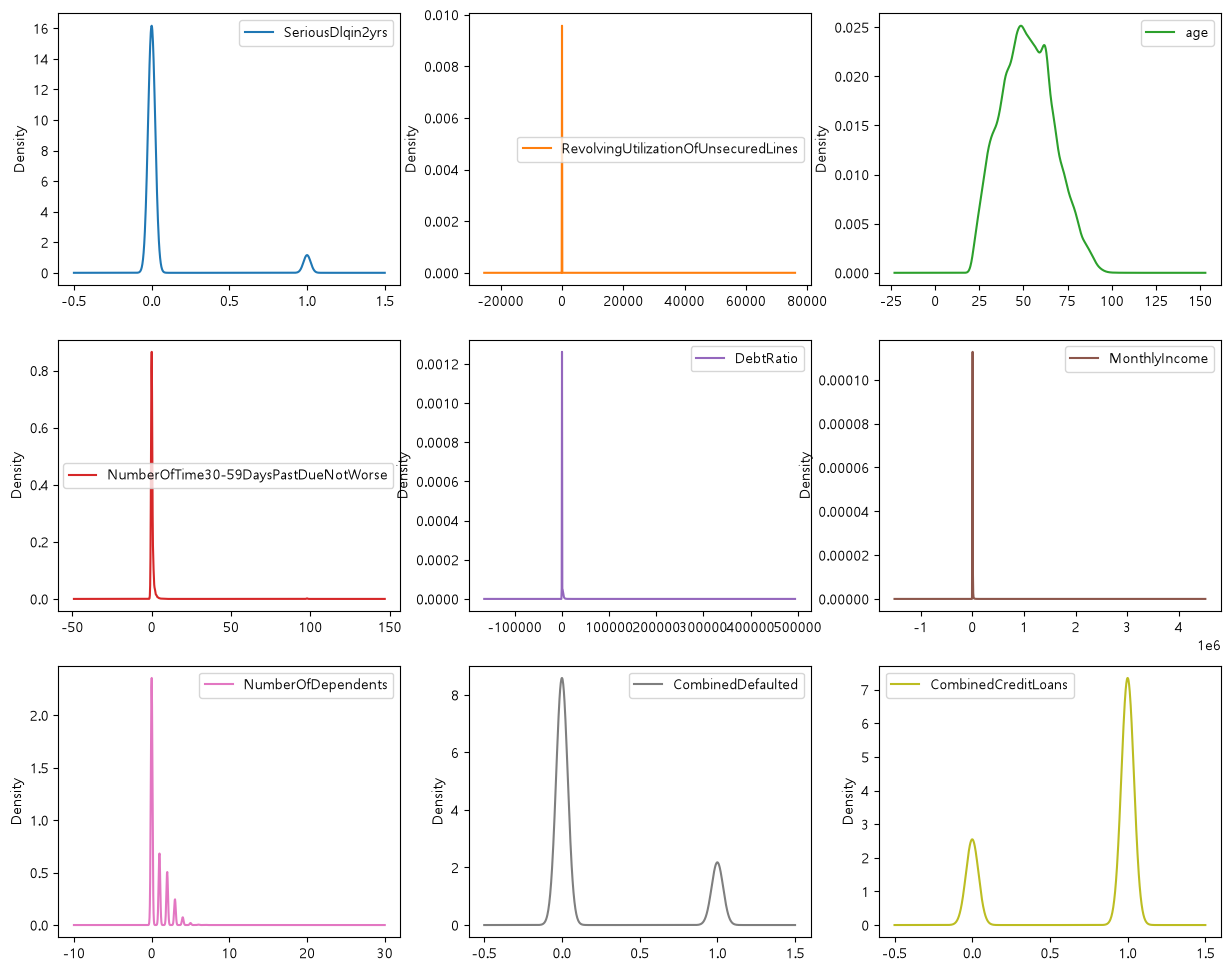

In [10]:
# 밀도 플롯
data.plot(kind='density', subplots=True, layout=(3, 3), sharex=False, figsize=(15, 12))

SeriousDlqin2yrs                           Axes(0.125,0.653529;0.227941x0.226471)
RevolvingUtilizationOfUnsecuredLines    Axes(0.398529,0.653529;0.227941x0.226471)
age                                     Axes(0.672059,0.653529;0.227941x0.226471)
NumberOfTime30-59DaysPastDueNotWorse       Axes(0.125,0.381765;0.227941x0.226471)
DebtRatio                               Axes(0.398529,0.381765;0.227941x0.226471)
MonthlyIncome                           Axes(0.672059,0.381765;0.227941x0.226471)
NumberOfDependents                             Axes(0.125,0.11;0.227941x0.226471)
CombinedDefaulted                           Axes(0.398529,0.11;0.227941x0.226471)
CombinedCreditLoans                         Axes(0.672059,0.11;0.227941x0.226471)
dtype: object

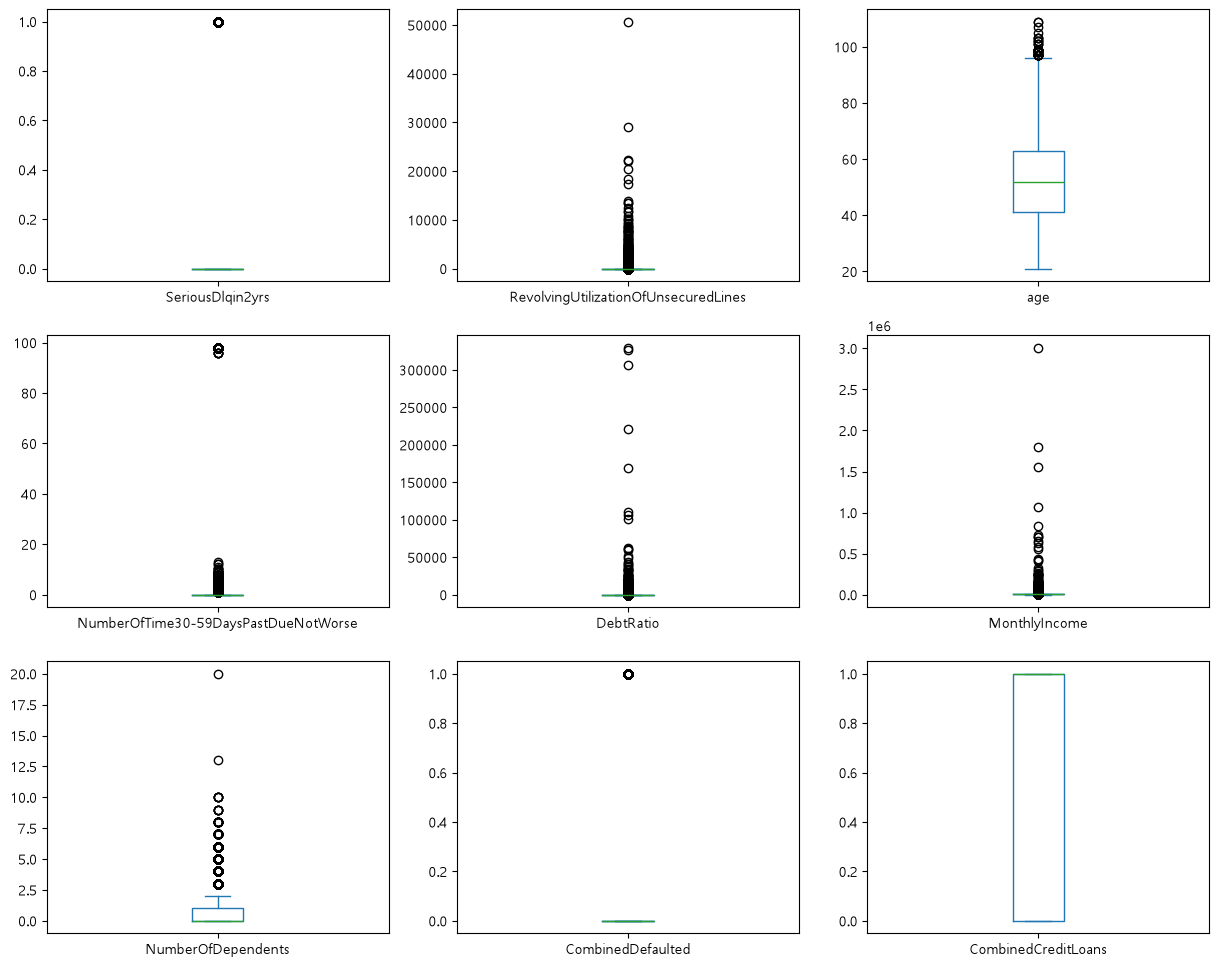

In [11]:
# 상자 수염 플롯
data.plot(kind='box', subplots=True, layout=(3, 3), sharex=False, sharey=False, figsize=(15, 12))

SeriousDlqin2yrs                           Axes(0.125,0.653529;0.227941x0.226471)
RevolvingUtilizationOfUnsecuredLines    Axes(0.398529,0.653529;0.227941x0.226471)
age                                     Axes(0.672059,0.653529;0.227941x0.226471)
NumberOfTime30-59DaysPastDueNotWorse       Axes(0.125,0.381765;0.227941x0.226471)
DebtRatio                               Axes(0.398529,0.381765;0.227941x0.226471)
MonthlyIncome                           Axes(0.672059,0.381765;0.227941x0.226471)
NumberOfDependents                             Axes(0.125,0.11;0.227941x0.226471)
CombinedDefaulted                           Axes(0.398529,0.11;0.227941x0.226471)
CombinedCreditLoans                         Axes(0.672059,0.11;0.227941x0.226471)
dtype: object

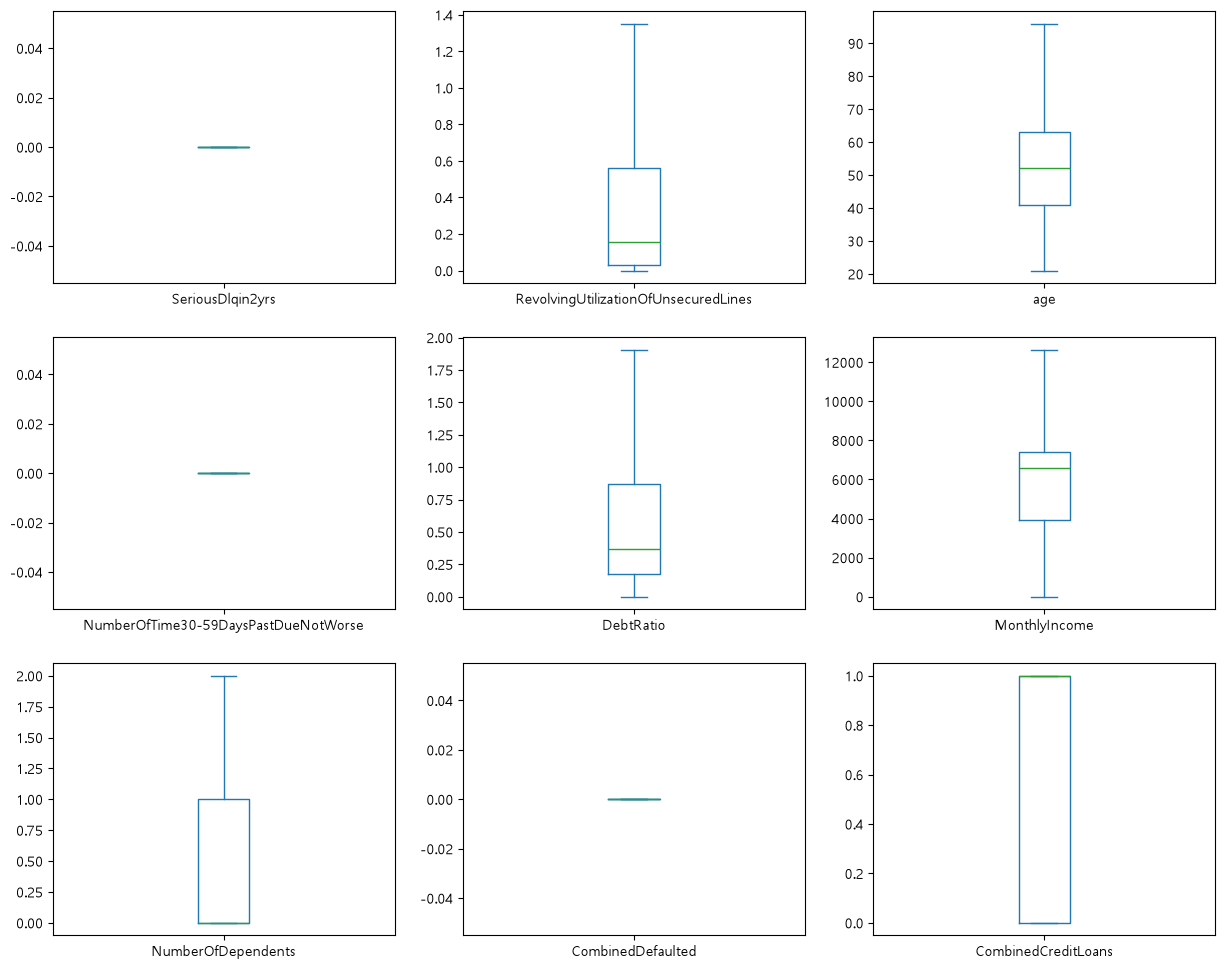

In [12]:
# 상자 수염 플롯 (이상치 제외)
data.plot(kind='box', subplots=True, layout=(3, 3), sharex=False, sharey=False, figsize=(15, 12), showfliers=False)

<Axes: >

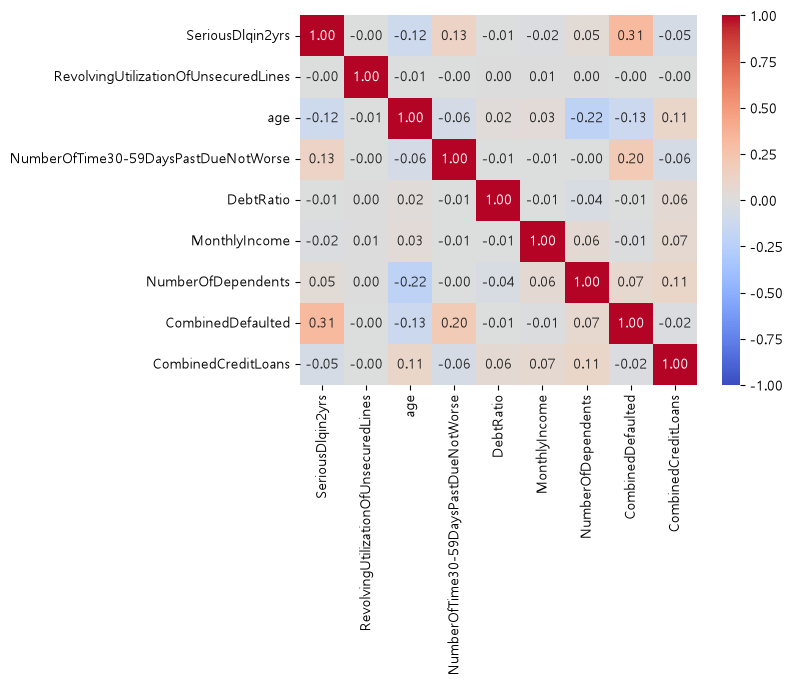

In [14]:
# 변수 간 상관관계 확인
corr = data.corr(method='pearson')

sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)

array([[<Axes: xlabel='SeriousDlqin2yrs', ylabel='SeriousDlqin2yrs'>,
        <Axes: xlabel='RevolvingUtilizationOfUnsecuredLines', ylabel='SeriousDlqin2yrs'>,
        <Axes: xlabel='age', ylabel='SeriousDlqin2yrs'>,
        <Axes: xlabel='NumberOfTime30-59DaysPastDueNotWorse', ylabel='SeriousDlqin2yrs'>,
        <Axes: xlabel='DebtRatio', ylabel='SeriousDlqin2yrs'>,
        <Axes: xlabel='MonthlyIncome', ylabel='SeriousDlqin2yrs'>,
        <Axes: xlabel='NumberOfDependents', ylabel='SeriousDlqin2yrs'>,
        <Axes: xlabel='CombinedDefaulted', ylabel='SeriousDlqin2yrs'>,
        <Axes: xlabel='CombinedCreditLoans', ylabel='SeriousDlqin2yrs'>],
       [<Axes: xlabel='SeriousDlqin2yrs', ylabel='RevolvingUtilizationOfUnsecuredLines'>,
        <Axes: xlabel='RevolvingUtilizationOfUnsecuredLines', ylabel='RevolvingUtilizationOfUnsecuredLines'>,
        <Axes: xlabel='age', ylabel='RevolvingUtilizationOfUnsecuredLines'>,
        <Axes: xlabel='NumberOfTime30-59DaysPastDueNotWorse', ylabel=

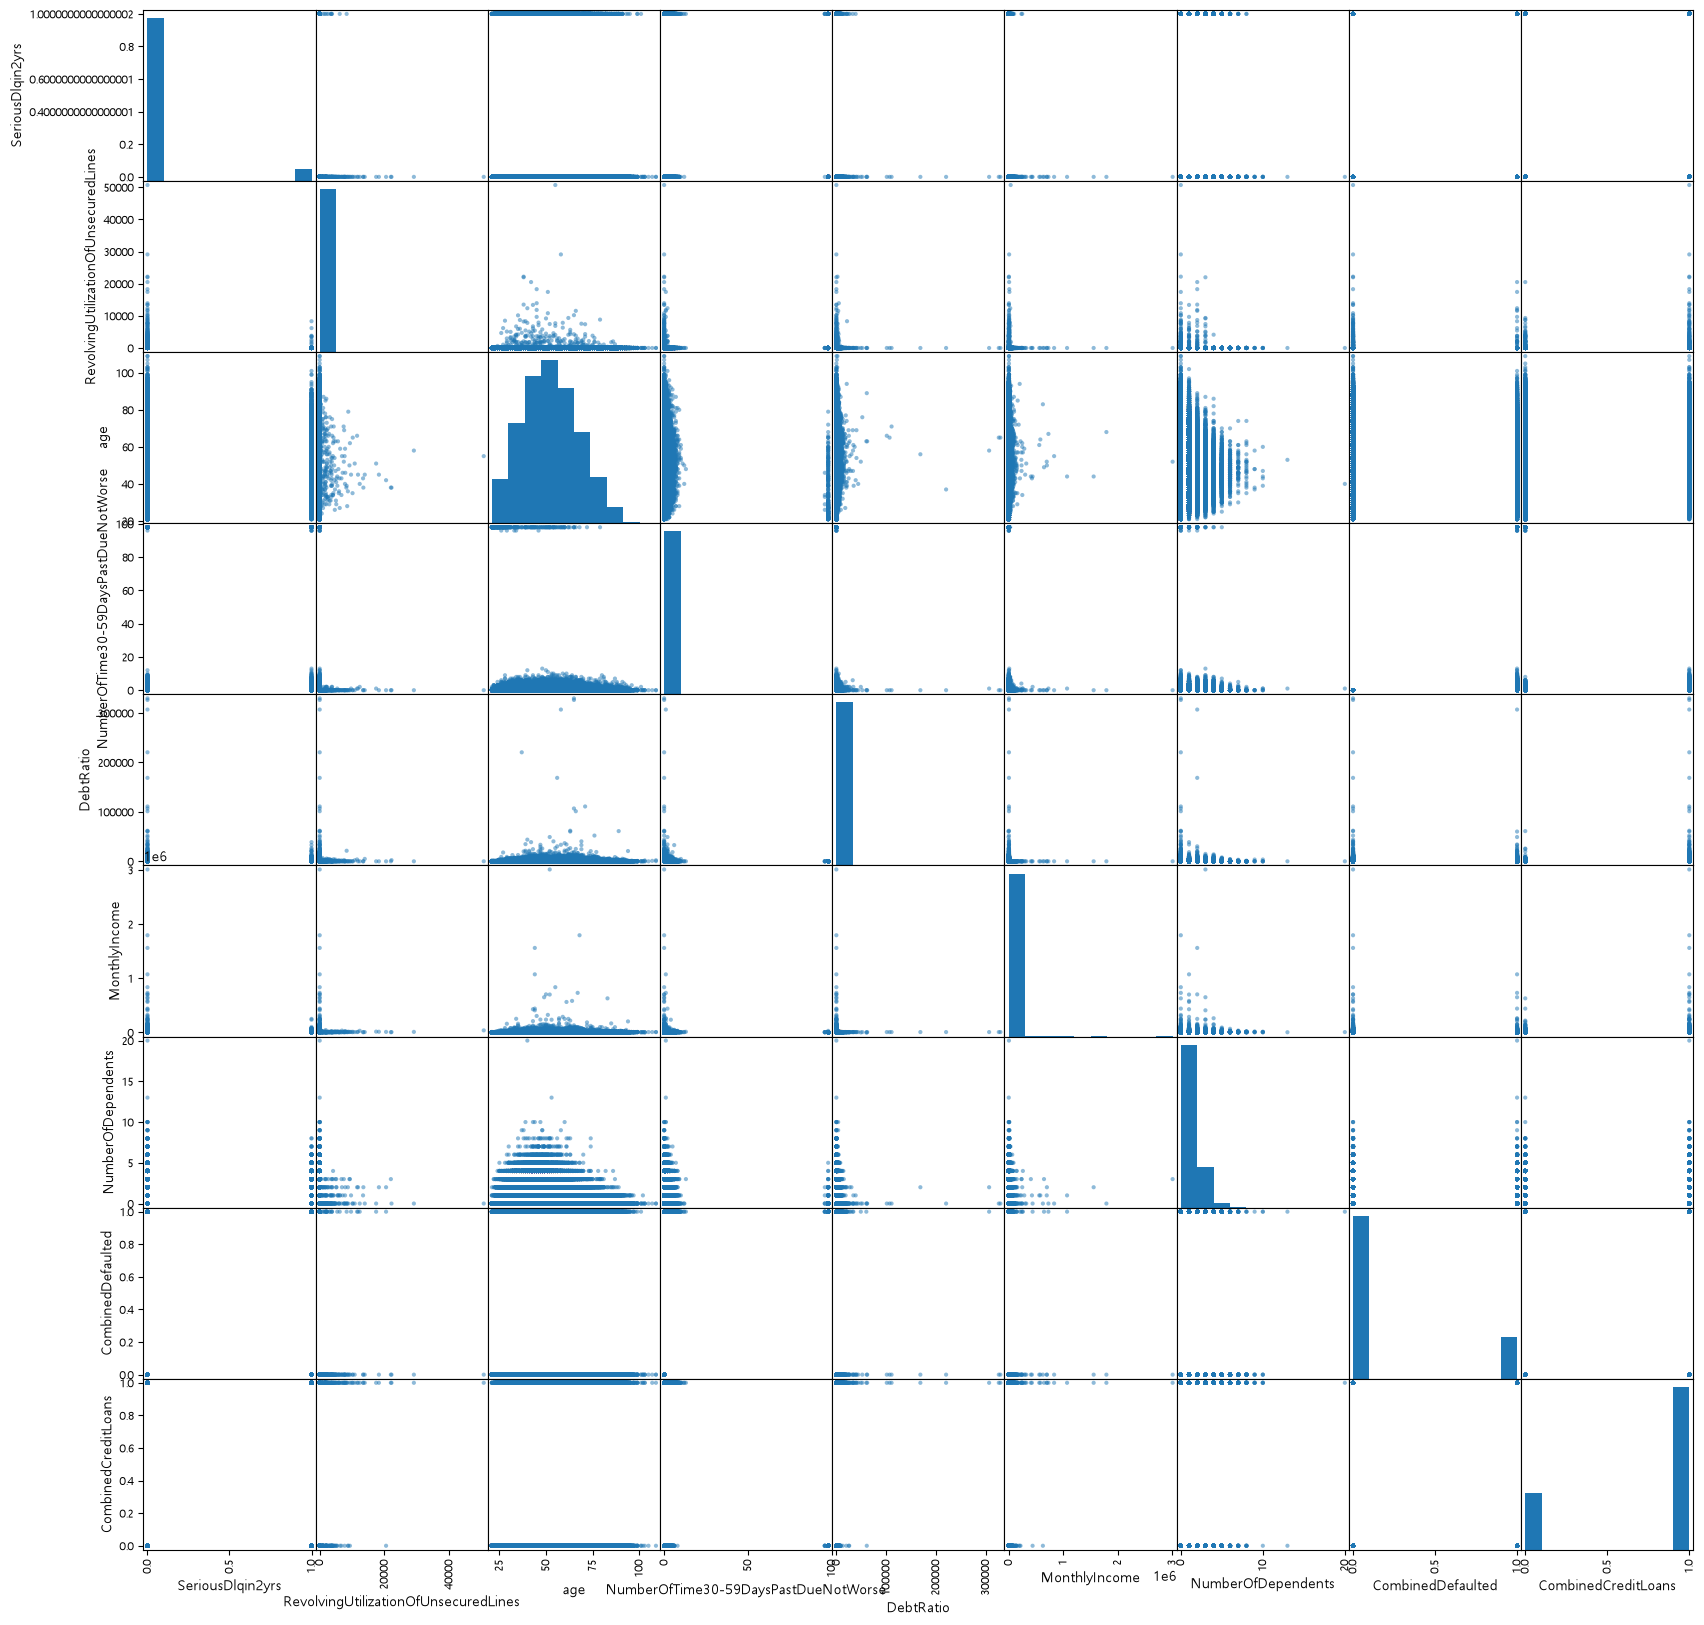

In [15]:
from pandas.plotting import scatter_matrix
scatter_matrix(data, figsize=[20, 20])
plt.show()